![Banner](./img/AI_Special_Program_Banner.jpg)  

# Sample solutions to NumPy exercises
---

In [1]:
import numpy as np

## Image manipulation
---

Images are nothing more than a *matrix of pixel values* for the computer - and therefore perfectly suited to be edited with NumPy! In this exercise, you will modify various aspects of an image by extracting and manipulating pixel values. To read the image and display it in Jupyter Notebook, you will need `matplotlib`. We are getting ahead of ourselves at this point, so you will be provided with the required code. You can install matplotlib with `conda install matplotlib`.

Import from `matplotlib`:

In [2]:
import matplotlib.pyplot as plt

Now we have to read in our image. The `imread()` method directly returns a **NumPy array**. We normalize the pixel values directly from `[0,255]` to `[0,1]`.

In [3]:
img = (plt.imread('./data/Sailing.jpg')/255).copy()

If we look at the `shape` of our array, we see that the image is in RGB format, with `(rows/height, splats/width, color channels)`.

In [4]:
img.shape

(1488, 1984, 3)

With the following function we can display the image array in Jupyter Notebook as an image:

In [5]:
def show_img(img, size=(15,10)):
    plt.figure(figsize=size)
    plt.imshow(img)

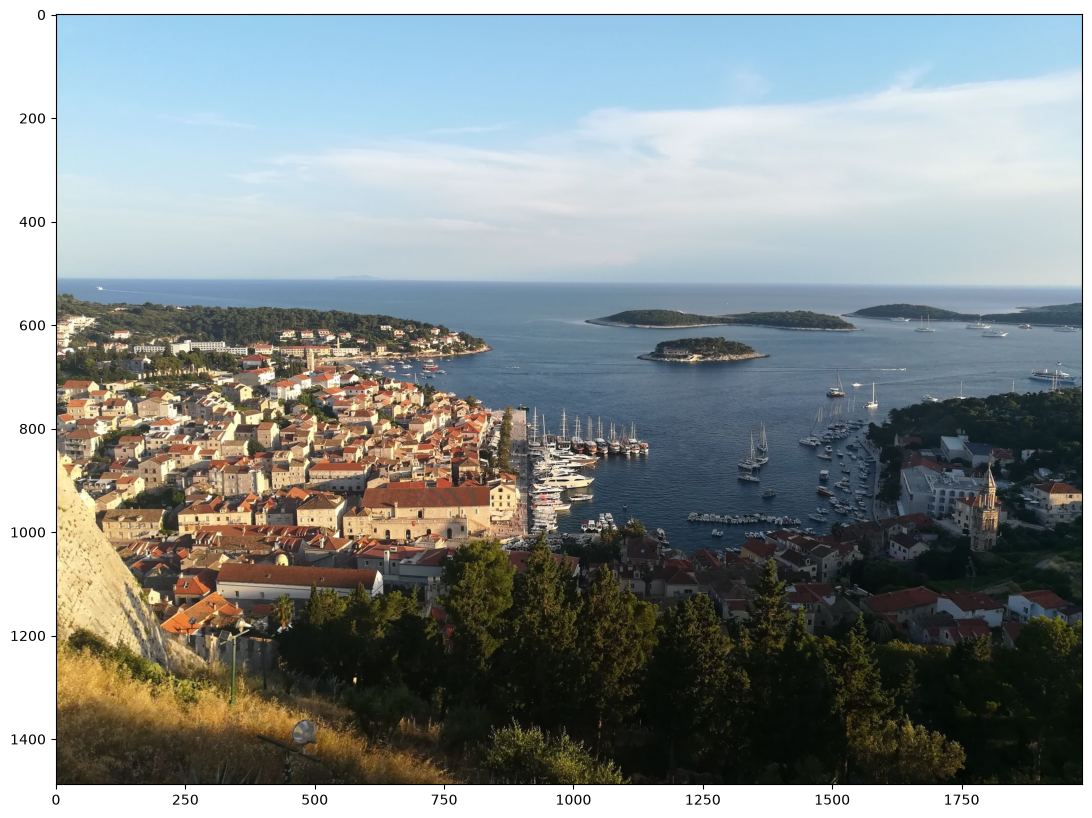

In [6]:
show_img(img)

Solve the following tasks with the help of NumPy:

* The image is to be mirrored vertically
* The image is to be rotated by 90
* Insert a black square with a size of 200 pixels exactly in the center of the image
* Increase the contrast by setting dark pixels (`<0.3`) completely to `0`. *Note*: `np.where()`

**Bonus task:** Blur the image (*blur effect*)! You can achieve this by clever **slicing** and **averaging** the values. You can visualize the process by "moving" a square (*filter*) over the image and determining the average value of the 4 pixel values within the square. Although the resulting image is reduced in size as a result, it corresponds to a blurred version of the original image due to the averaging of the values. You can see this filter concept here:

![LE5 Ex1](img/numpy_ex1.png)

In the case of Numpy, you can dispense with the use of `for` loops and use clever slicing. To do this, you should extract the top, bottom, left and right pixel values of the image and add these (in each case reduced matrices) and then average them. This is similar to superimposing several identical overhead transparencies, each of which is shifted slightly. The result is a slightly blurred, reduced version of the original image. *Note*: A single averaging of the images leads to a barely noticeable blur effect. You should therefore repeat the operation several times (~50) to achieve a clearly visible effect. Think about loops and functions...

## Solution
---

* Mirror image vertically:

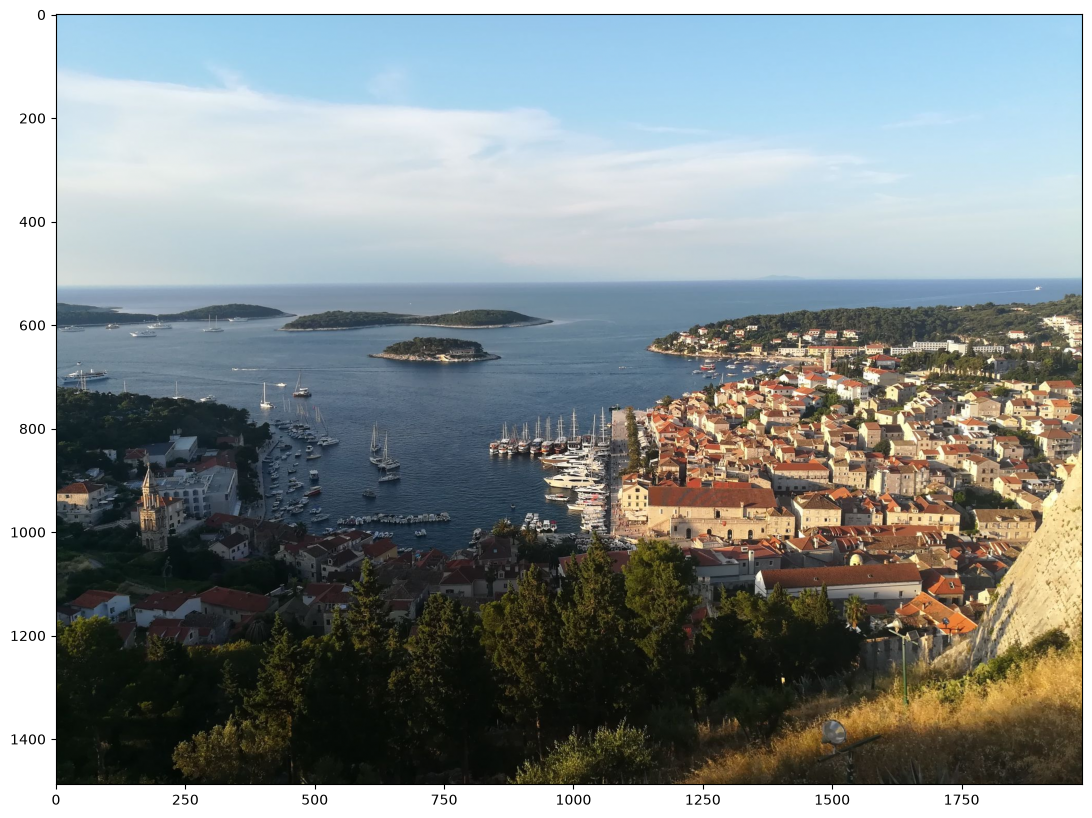

In [7]:
show_img(img[:,::-1,])

* Rotate:

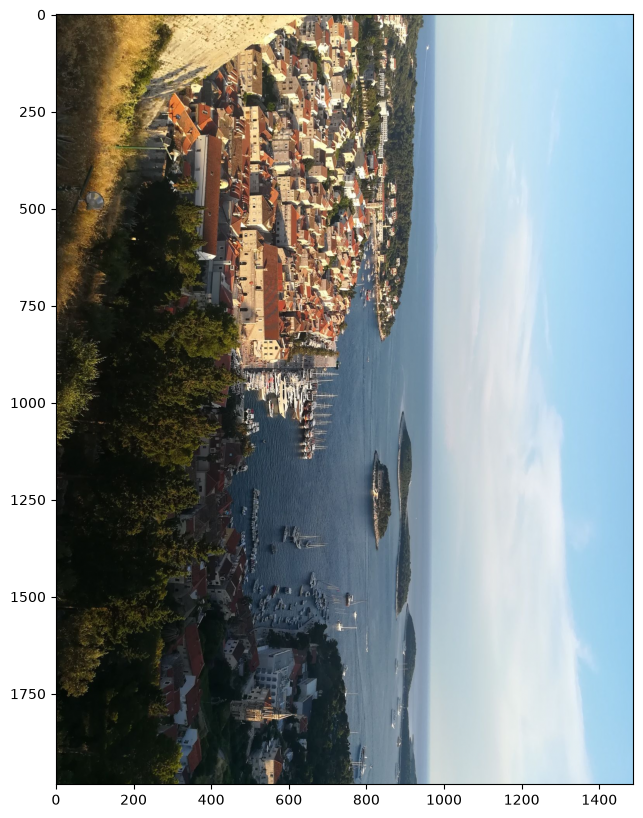

In [8]:
show_img(np.rot90(img,3))

* Black square

In [9]:
img_square = img.copy()

In [10]:
half_height = int(len(img_square[:,0,0])/2)

In [11]:
half_length = int(len(img_square[0,:,0])/2)

In [12]:
img_square[half_height-100:half_height+100, half_length-100:half_length+100, :] = 0

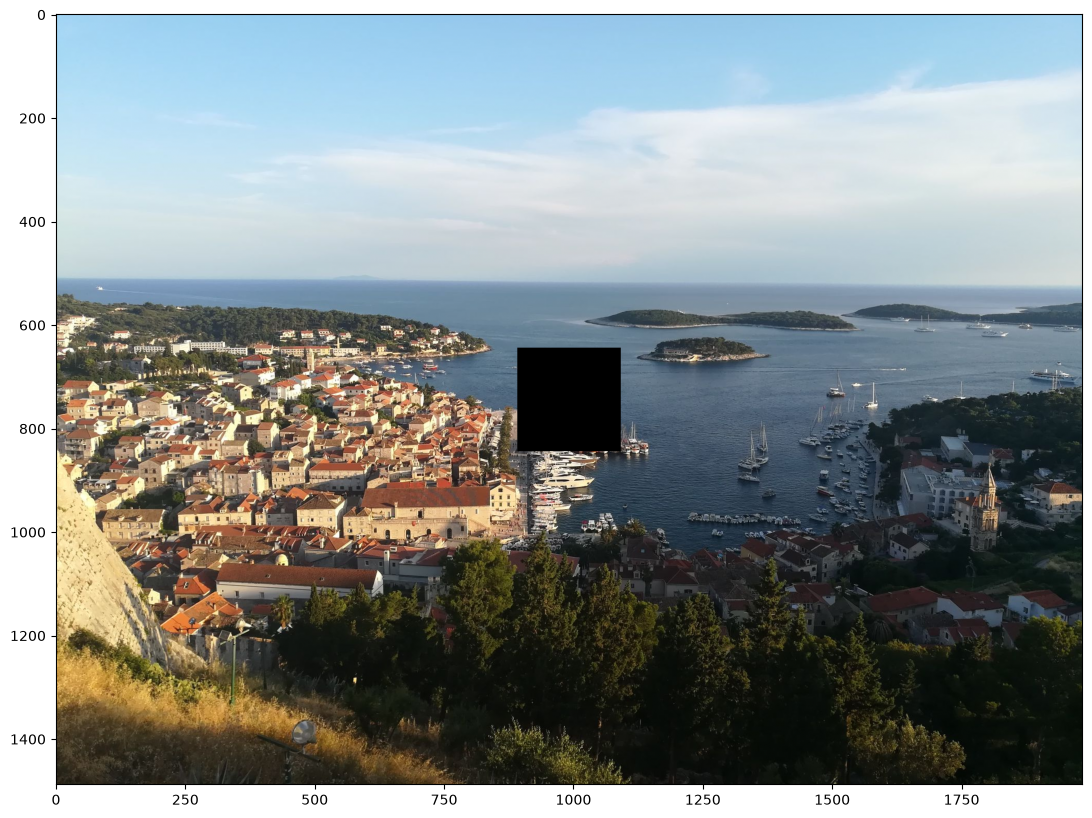

In [13]:
show_img(img_square)

* Increase contrast, deactivate dark pixels completely:

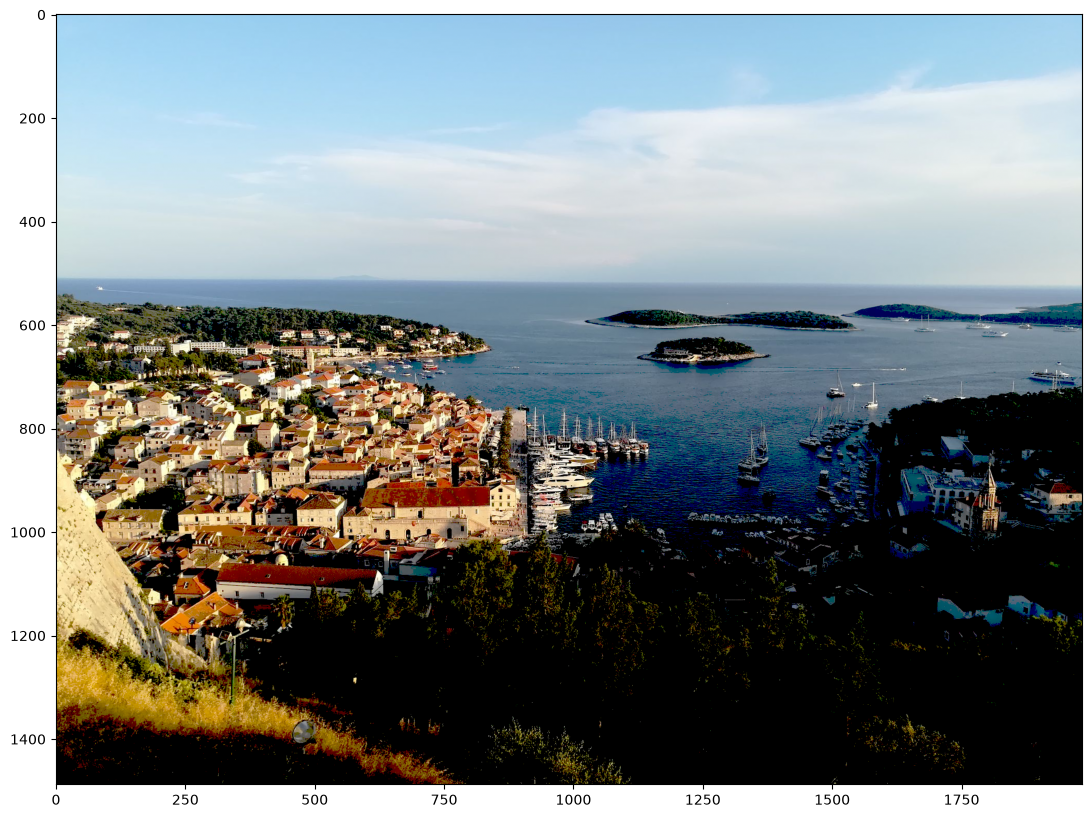

In [14]:
show_img(np.where(img < 0.3, 0, img))

* Smooth

In [15]:
def smooth(img):
    avg_img =(    img[ :-2 ,1:-1]  # top
                + img[2:   ,1:-1]  # bottom
                + img[1:-1 , :-2]  # left
                + img[1:-1 ,2:  ]  # right
                ) / 4.0
    return avg_img

Alternatively, the **corners** of the image can also be used (better preservation of the resolution!):

```python
def smooth(img):
    avg_img =( img[ :-1 ,-1: ] # top-left
                + img[1: , :-1] # bottom-left
                + img[ :-1 ,1: ] # top-right
                + img[1: ,1: ] # bottom-right
                ) / 4.0
    return avg_img
```

In [16]:
avg_img = smooth(img) # reduction of 2 pixels in two dimensions, very small blur effect

In [17]:
for num in range(50):   # reduction of 100 pixel, visible blur effect
    avg_img = smooth(avg_img)   

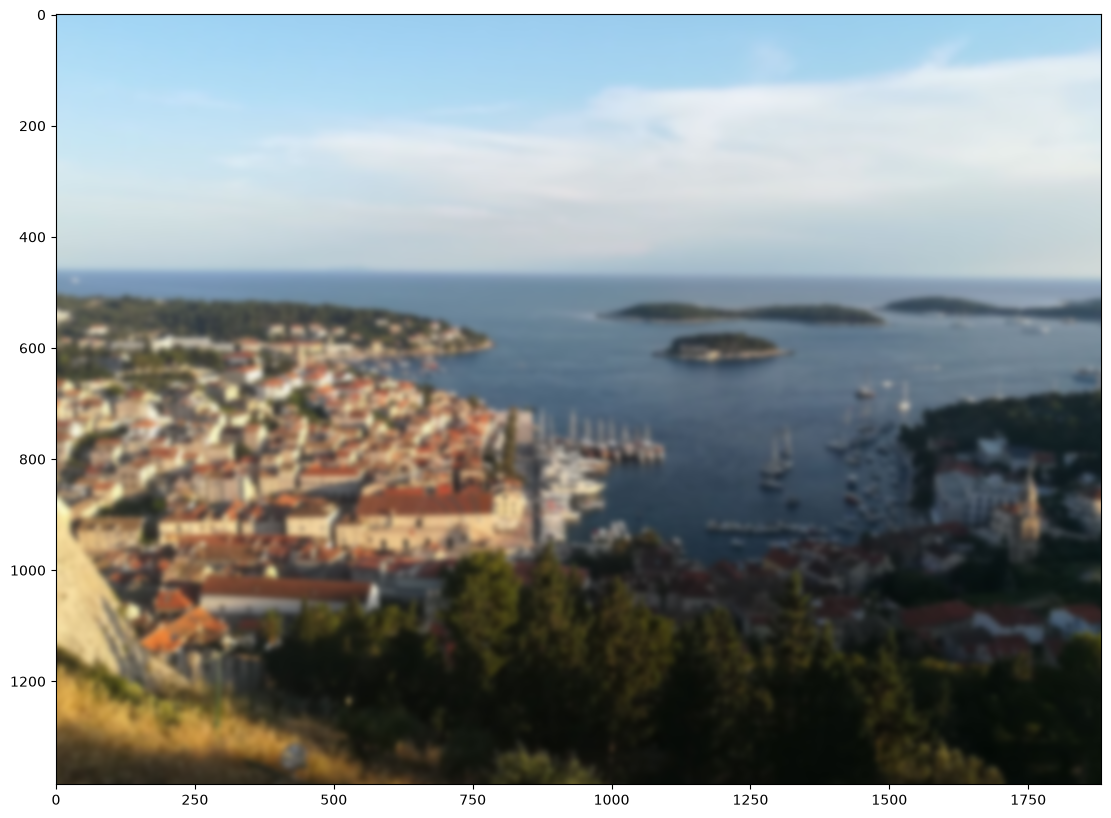

In [18]:
show_img(avg_img)

## Analysis of wind speeds
---

### 1. Reading in data

In [19]:
wind_data = np.loadtxt('./data/wind.data')


In [20]:
wind_data

array([[2.001e+03, 1.000e+00, 1.000e+00, ..., 1.258e+01, 1.850e+01,
        1.504e+01],
       [2.001e+03, 1.000e+00, 2.000e+00, ..., 9.670e+00, 1.754e+01,
        1.383e+01],
       [2.001e+03, 1.000e+00, 3.000e+00, ..., 7.670e+00, 1.275e+01,
        1.271e+01],
       ...,
       [2.018e+03, 1.200e+01, 2.900e+01, ..., 1.642e+01, 1.888e+01,
        2.958e+01],
       [2.018e+03, 1.200e+01, 3.000e+01, ..., 1.212e+01, 1.467e+01,
        2.879e+01],
       [2.018e+03, 1.200e+01, 3.100e+01, ..., 1.138e+01, 1.208e+01,
        2.208e+01]], shape=(6574, 15))

In [21]:
data = wind_data[:, 3:]

In [22]:
data

array([[15.04, 14.96, 13.17, ..., 12.58, 18.5 , 15.04],
       [14.71, 16.88, 10.83, ...,  9.67, 17.54, 13.83],
       [18.5 , 16.88, 12.33, ...,  7.67, 12.75, 12.71],
       ...,
       [14.  , 10.29, 14.42, ..., 16.42, 18.88, 29.58],
       [18.5 , 14.04, 21.29, ..., 12.12, 14.67, 28.79],
       [20.33, 17.41, 27.29, ..., 11.38, 12.08, 22.08]], shape=(6574, 12))

### 2. Overall statistics

In [23]:
print(f"Minimum: {data.min()}")
print(f"Maximum: {data.max()}")
print(f"Average: {data.mean()}")
print(f"Standard deviation: {data.std()}")

Minimum: 0.0
Maximum: 42.54
Average: 10.22837377040868
Standard deviation: 5.603840181095793


### 3. Statistics of the individual regions for all days

In [24]:
print(f"Minimum: {data.min(axis=0)}")
print(f"Maximum: {data.max(axis=0)}")
print(f"Average: {data.mean(axis=0)}")
print(f"Standard deviation: {data.std(axis=0)}")

Minimum: [0.67 0.21 1.5  0.   0.13 0.   0.   0.   0.   0.04 0.13 0.67]
Maximum: [35.8  33.37 33.84 28.46 37.54 26.16 30.37 31.08 25.88 28.21 42.38 42.54]
Average: [12.36371463 10.64644813 11.66010344  6.30627472 10.45688013  7.09225434
  9.7968345   8.49442044  8.49581838  8.70726803 13.121007   15.59946152]
Standard deviation: [5.61918301 5.26820081 5.00738377 3.60513309 4.93536333 3.96838126
 4.97689374 4.49865783 4.16746101 4.50327222 5.83459319 6.69734719]


### 4. Statistics of the individual days for all regions

In [25]:
print(f"Minimum: {data.min(axis=1)}")
print(f"Maximum: {data.max(axis=1)}")
print(f"Average: {data.mean(axis=1)}")
print(f"Standard deviation: {data.std(axis=1)}")

Minimum: [9.29 6.5  6.17 ... 8.71 9.13 9.59]
Maximum: [18.5  17.54 18.5  ... 29.58 28.79 27.29]
Average: [13.09666667 11.79833333 11.34166667 ... 14.89       15.3675
 15.4025    ]
Standard deviation: [2.5773188  3.28972854 3.50543348 ... 5.51175108 5.30456427 5.45971172]


### 5. Region of the daily maximum

In [26]:
print(f'Region with daily maximum: {data.argmax(axis=1)}')

Region with daily maximum: [10 10  0 ... 11 11  2]


### 6. Date of the largest measured value

In [27]:
max_row, max_col = np.nonzero(data == data.max())

In [28]:
print(f'year: {int(wind_data[max_row, 0].item())}')
print(f'month: {int(wind_data[max_row, 1].item())}')
print(f'day: {int(wind_data[max_row, 2].item())}')

year: 2006
month: 12
day: 2


### 7. Statistics for january

In [29]:
january_indices = wind_data[:,1] == 1

In [30]:
january_data = data[january_indices]

In [31]:
print(f"Average january: {january_data.mean(axis=0)}")

Average january: [14.86955197 12.92166667 13.29962366  7.19949821 11.67571685  8.05483871
 11.81935484  9.5094086   9.54320789 10.05356631 14.55051971 18.02876344]
